In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [6]:
# Read csv file
path = "F:/Users/MSR/Downloads/student-mat.csv"
# df_0 = pd.read_csv(path+"student-mat.csv", sep=";")
df_0 = pd.read_csv(path, sep=";")

In [7]:
df_0.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [9]:
# Display Column and type
df_0.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [13]:
df_0.dtypes

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

In [17]:
# Intro to High_G3
df_0['High_G3'] = np.where(df_0['G3'] > 10, 'High', 'Moderate')

df_0[['High_G3', 'G3']].head

<bound method NDFrame.head of       High_G3  G3
0    Moderate   6
1    Moderate   6
2    Moderate  10
3        High  15
4    Moderate  10
..        ...  ..
390  Moderate   9
391      High  16
392  Moderate   7
393  Moderate  10
394  Moderate   9

[395 rows x 2 columns]>

In [18]:
# Print the Distribution
print("Distribution of Samples High in G3")
print(df_0['High_G3'].value_counts())

Distribution of Samples High in G3
High_G3
High        209
Moderate    186
Name: count, dtype: int64


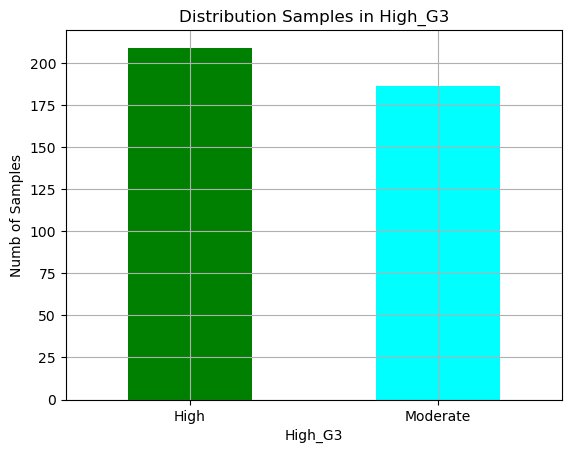

In [22]:
df_0['High_G3'].value_counts().plot(kind="bar", title="Distribution Samples in High_G3", color=['green', 'cyan'])

plt.xlabel('High_G3')
plt.ylabel("Numb of Samples")
plt.xticks(rotation=0)
plt.grid(True)
plt.show()

In [24]:
# Remove G3 column
df = df_0.drop('G3', axis=1)

# Set x = All features except G3
X = df.drop('High_G3', axis=1)

# Set y = High_G3 {what we are predicting}
y = df['High_G3']

print(df.head())
X.head()

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2   High_G3  
0      4        3      4     1     1      3        6   5   6  Moderate  
1      5        3      3     1     1      3        4   5   5  Moderate  
2      4        3      2     2     3      3       10   7   8  Moderate  
3      3        2      2     1     1      5        2  15  14      High  
4      4        3      2     1     2      5        4   6  10  Moderate  

[5 rows x 33 columns]


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,4,3,4,1,1,3,6,5,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,no,5,3,3,1,1,3,4,5,5
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,no,4,3,2,2,3,3,10,7,8
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,3,2,2,1,1,5,2,15,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,4,3,2,1,2,5,4,6,10


In [26]:
# Converting categoricat figures as one hot encoding
X = pd.get_dummies(X, drop_first=True).astype(float)

X.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18.0,4.0,4.0,2.0,2.0,0.0,4.0,3.0,4.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,17.0,1.0,1.0,1.0,2.0,0.0,5.0,3.0,3.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,15.0,1.0,1.0,1.0,2.0,3.0,4.0,3.0,2.0,2.0,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0
3,15.0,4.0,2.0,1.0,3.0,0.0,3.0,2.0,2.0,1.0,...,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,16.0,3.0,3.0,1.0,2.0,0.0,4.0,3.0,2.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0


In [27]:
# Convert y to numbers: High->1, Moderate->0
y = np.where(y == 'High', 1, 0)

y.head()

AttributeError: 'numpy.ndarray' object has no attribute 'head'

In [32]:
# Standard Scaler Feature
sclr = StandardScaler()
xscl = sclr.fit_transform(X)

# Perform train test split 80-20
xtrn, xtst, ytrn, ytst = train_test_split(xscl, y, test_size=0.2, random_state=63)

print(xscl.shape)
print("----- After Train Test Split----")
print(xtrn.shape)
print(xtst.shape)
print(ytst.shape)
print(ytrn.shape)

(395, 33)
(395, 41)
----- After Train Test Split----
(316, 41)
(79, 41)
(79,)
(316,)


In [65]:
# Define Model Cost Function

# Sigmoid Activation: Converts z into a probability between 1 and 0
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Cost Function: Binary Cross Entorpy
def cost_function(X, y, w, b):
    yPred = sigmoid(np.dot(X,w) + b)
    eps = 1e-12                       # Small Value: Avoid log(0) at all cost
    return -np.mean(y * np.log(yPred + eps) + (1-y) * np.log(1-yPred+eps))

# Gradient of 'Cost' with respect to w and b
def gradients(X, y, w, b):
    m = X.shape[0]
    yPred = sigmoid(np.dot(X, w) + b)
    dw = np.dot(X.T, (yPred - y)) / m
    db = np.sum(yPred - y) / m
    return dw, db

# Predict Class1:  (High) if probability => 0.5
def predict(X, w, b):
    return np.where(sigmoid(np.dot(X, w) + b) >= 0.5, 1, 0)

In [66]:
# Gradient Descent: Plot at each Epoch
# Batch Gradient Descent
# Set Hyper Parameter

nFeature = xtrn.shape[1]
w = np.zeros(nFeature) # Initial Weight
b = 0                  # Initial Bias
lRate = 0.1            # Learn Rate
epoch = 100

In [67]:
print("---- Batch Gradient Descent ---")
print(nFeature)
print(lRate)
print(epoch)

# Store the cost at each epoch to Plot later
bgd_Data = []


---- Batch Gradient Descent ---
41
0.1
100


In [68]:
# ----- Run: Batch Gradient descent Loop
# All train samples are used for the prediction
# -------- weights updated ONCE per epoch

for i in range(epoch):
    # Cost at the current weight
    currentCost = cost_function(xtrn, ytrn, w, b)

    # Gradient using whole train dataset
    dw, db = gradients(xtrn, ytrn, w, b)

    # Move w, b to the other side of the gradient
    w = w -lRate * dw
    b = b - lRate * db

    # Cost after Update
    newCost = cost_function(xtrn, ytrn, w, b)

    bgd_Data.append({
        'Epoch' : i+1,
        'Cost' : currentCost,
        'New_Cost': newCost,
        'Gradient |dw|' : np.linalg.norm(dw),
        'db' : db,
    })

    w_bdg, b_bdg = w, b

In [69]:
# Create and Build the DataFrame

bdg_df = pd.DataFrame(bgd_Data).set_index('Epoch')

print(bdg_df.to_string)


<bound method DataFrame.to_string of            Cost  New_Cost  Gradient |dw|        db
Epoch                                             
1      0.693147  0.655967       0.619782 -0.028481
2      0.655967  0.623635       0.577625 -0.027786
3      0.623635  0.595389       0.539490 -0.027083
4      0.595389  0.570570       0.505273 -0.026373
5      0.570570  0.548627       0.474691 -0.025664
...         ...       ...            ...       ...
96     0.228872  0.228099       0.087348 -0.011070
97     0.228099  0.227338       0.086715 -0.011031
98     0.227338  0.226587       0.086093 -0.010992
99     0.226587  0.225847       0.085481 -0.010953
100    0.225847  0.225117       0.084881 -0.010915

[100 rows x 4 columns]>


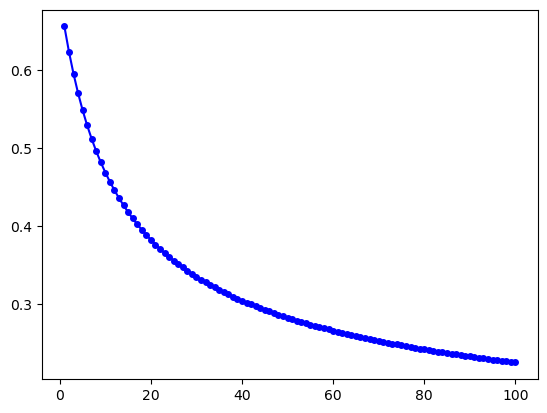

In [70]:
# Plot Cost Function at each Epoch
plt.plot(bdg_df.index, bdg_df['New_Cost'], 'bo-', markersize = 4, label="Batch GD Cost")

plt.show()

In [71]:
# Stochastic Gradient Descent

# Set Hyperparameters
w = np.zeros(nFeature)
b = 0.0
lRate = 0.01
epoch = 100
np.random.seed(63)

In [72]:
print("---- Stochiastic Gradient Descent ---")
print(nFeature)
print(lRate)
print(epoch)

# Store each epoch for later plot
sgd_data = []


---- Stochiastic Gradient Descent ---
41
0.01
100


In [73]:
# --- Run Stochiastic Gradient Descent Loop ---
# In SDG weights are updated after every loop
# Tere are m updates in one epoch

m = xtrn.shape[0]

for i in range(epoch):
    # Cost at start of the Epoch
    currentCost = cost_function(xtrn, ytrn, w, b)

    # Shuffle the sample at every epoch
    indices = np.random.permutation(m)

    for j in indices:
        xj = xtrn[j:j+1]
        yj = ytrn[j:j+1]

        # Gradient using one sample
        dw, db = gradients(xj, yj, w, b)

        # Move the w, b to the other side of the gradient
        w = w - lRate * dw
        b = b - lRate * db


        # Update w, b
        newCost = cost_function(xtrn, ytrn, w, b)

        sgd_data.append({
            'Epoch': i+1,
            'Cost' : currentCost,
            'Updates in Epoch' : m,
            'New Cost' : newCost,
        })

    w_sgd, b_sgd = w, b

In [74]:
# Create and Print the DataFrame

sgd_df = pd.DataFrame(sgd_data).set_index('Epoch')

# print(sgd_df.to_string(float_format="%.4f"))

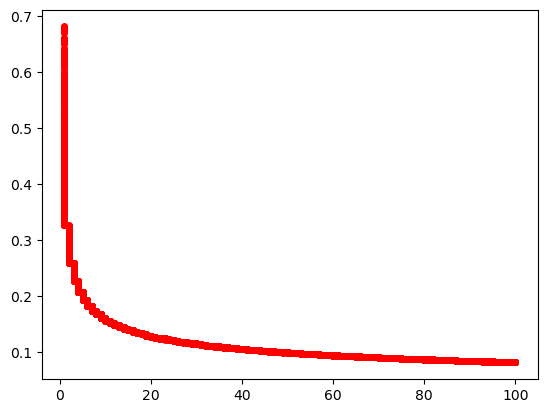

In [75]:
# Plot Cost Function

plt.plot(sgd_df.index, sgd_df['New Cost'], 'ro-', markersize=4, label='stochastic GD Cost')

plt.show()

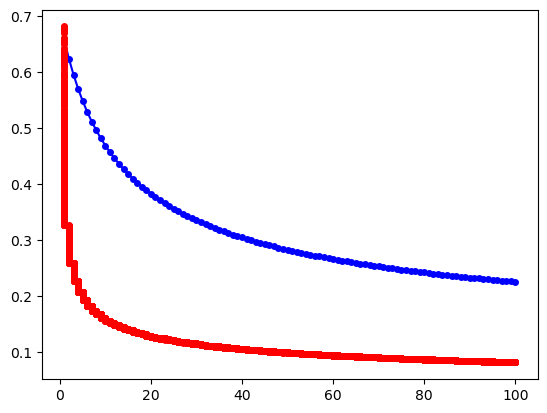

In [76]:
# Compare the 2 models BGD, SGD

plt.plot(bdg_df.index, bdg_df['New_Cost'], 'bo-', markersize=4, label='Batch GD Cost')
plt.plot(sgd_df.index, sgd_df['New Cost'], 'ro-', markersize=4, label='Stochastic GD Cost')



In [99]:
# ------- Evaluate Precision Accuracy
labels = ['Moderate', 'High']

def evaluate(name, w, b):
    yPred = predict(xtst, w, b)

    print(accuracy_score(ytst, yPred))
    print(precision_score(ytst, yPred))
    print(recall_score(ytst, yPred))
    print(f1_score(ytst, yPred))

    print(classification_report(ytst, yPred, target_names=labels))

    cm = confusion_matrix(ytst, yPred)
    print(cm)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap='Blues')
    plt.show

    return yPred

    

0.8607594936708861
0.8780487804878049
0.8571428571428571
0.8674698795180723
              precision    recall  f1-score   support

    Moderate       0.84      0.86      0.85        37
        High       0.88      0.86      0.87        42

    accuracy                           0.86        79
   macro avg       0.86      0.86      0.86        79
weighted avg       0.86      0.86      0.86        79

[[32  5]
 [ 6 36]]


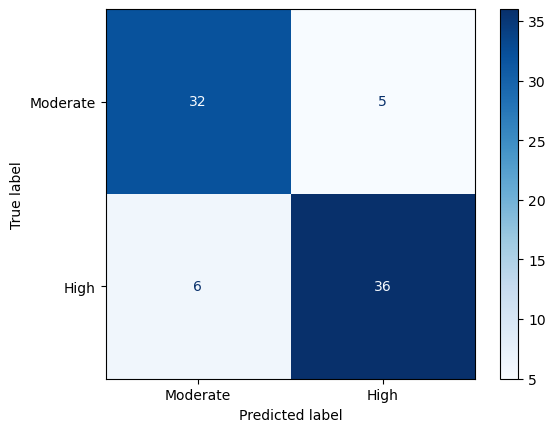

In [100]:
y_pred_bdg = evaluate('',w_bdg, b_bdg)

0.8481012658227848
0.8409090909090909
0.8809523809523809
0.8604651162790697
              precision    recall  f1-score   support

    Moderate       0.86      0.81      0.83        37
        High       0.84      0.88      0.86        42

    accuracy                           0.85        79
   macro avg       0.85      0.85      0.85        79
weighted avg       0.85      0.85      0.85        79

[[30  7]
 [ 5 37]]


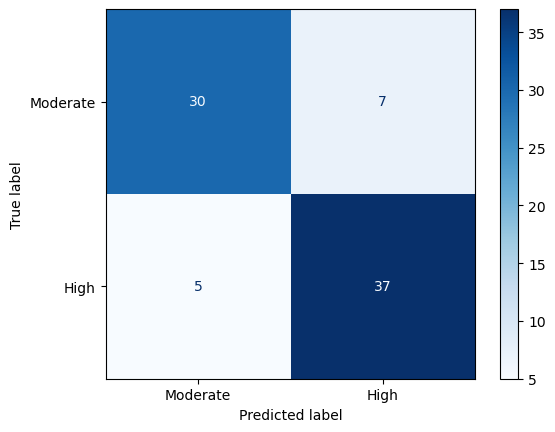

In [103]:
y_pred_sdg = evaluate('Stochastic Gradient Descent', w_sgd, b_sgd)

In [107]:
# Summary Table

summary = []

for name, yPred in [('Batch GD', y_pred_bdg), ('Stochastic GD', y_pred_sdg)]:
    summary.append({
        'Model':name,
        'Accuracy': accuracy_score(ytst, yPred),
        'Precision':  precision_score(ytst, yPred),
        'Recall': recall_score(ytst, yPred),
        'F1-score': f1_score(ytst , yPred)
    })

summary_df = pd.DataFrame(summary).set_index('Model')
print(summary_df)

               Accuracy  Precision    Recall  F1-score
Model                                                 
Batch GD       0.860759   0.878049  0.857143  0.867470
Stochastic GD  0.848101   0.840909  0.880952  0.860465
